# Wayback coverage scan — how much of Ruwiki can we actually mine?

Interactive version of the coverage scan, so we can see exactly what's being pulled at each step instead of trusting an opaque background script.

Goal: find out, article by article, how much of `ru.ruwiki.ru` the Internet Archive has actually captured — total captures, unique articles, and how that coverage spreads over time (June 2023 → now).

Run cells top to bottom. The full scan (Step 3) is the slow one — it prints progress per page and saves a checkpoint as it goes, so you can interrupt the kernel at any point without losing what's already been pulled.

In [2]:
import sys
sys.path.append('../src')

import json
import time
from pathlib import Path

import pandas as pd
import requests
from tqdm.auto import tqdm

from wayback_harvest import CDX_API, USER_AGENT, get_with_retries

session = requests.Session()
session.headers['User-Agent'] = USER_AGENT

DATA_DIR = Path('../data/interim')
DATA_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PATH = DATA_DIR / 'cdx_full_index_checkpoint.parquet'

CDX_API, USER_AGENT

('https://web.archive.org/cdx/search/cdx',
 'ruwiki-diachronic-research/0.1 (contact: rasikahendrix@gmail.com)')

## Step 1 — how many index pages does the CDX API have for `ru.ruwiki.ru/wiki/*`?

This is a cheap metadata call, not a data pull — it just tells us how many pages we'll need to page through.

In [3]:
num_pages_resp = get_with_retries(
    session, CDX_API, params={'url': 'ru.ruwiki.ru/wiki/*', 'showNumPages': 'true'}
)
num_pages = int(num_pages_resp.text.strip())
print(f'CDX reports {num_pages} pages for ru.ruwiki.ru/wiki/*')

CDX reports 111 pages for ru.ruwiki.ru/wiki/*


## Step 2 — preview a single page, so we know what we're actually getting

Each row: `urlkey, timestamp, original (the real URL), mimetype, statuscode, digest (content hash), length`.

In [4]:
resp = get_with_retries(
    session, CDX_API, params={'url': 'ru.ruwiki.ru/wiki/*', 'output': 'json', 'page': 0}
)
rows = resp.json()
header, records = rows[0], rows[1:]
page0_df = pd.DataFrame(records, columns=header)
print(f'page 0: {len(page0_df)} rows')
page0_df.head(20)

page 0: 1266 rows


,urlkey,timestamp,original,mimetype,statuscode,digest,length
0,"ru,ruwiki,ru)/wiki",20230713083707,https://ru.ruwiki.ru/wiki,text/html,301,3I42H3S6NNFQ2MSVX7XZKYAYSCX5QBYJ,645
1,"ru,ruwiki,ru)/wiki",20230905160055,https://ru.ruwiki.ru/wiki/,text/html,301,3I42H3S6NNFQ2MSVX7XZKYAYSCX5QBYJ,832
2,"ru,ruwiki,ru)/wiki",20240111065425,https://ru.ruwiki.ru/wiki/,warc/revisit,-,3I42H3S6NNFQ2MSVX7XZKYAYSCX5QBYJ,709
3,"ru,ruwiki,ru)/wiki",20240112014018,https://ru.ruwiki.ru/wiki/,text/html,301,3I42H3S6NNFQ2MSVX7XZKYAYSCX5QBYJ,521
4,"ru,ruwiki,ru)/wiki",20240114043518,https://ru.ruwiki.ru/wiki/,text/html,301,3I42H3S6NNFQ2MSVX7XZKYAYSCX5QBYJ,712
5,"ru,ruwiki,ru)/wiki",20240115123717,https://ru.ruwiki.ru/wiki/,text/html,301,3I42H3S6NNFQ2MSVX7XZKYAYSCX5QBYJ,716
6,"ru,ruwiki,ru)/wiki",20240127203135,https://ru.ruwiki.ru/wiki/,warc/revisit,-,3I42H3S6NNFQ2MSVX7XZKYAYSCX5QBYJ,790
7,"ru,ruwiki,ru)/wiki",20240205115120,https://ru.ruwiki.ru/wiki/,text/html,301,3I42H3S6NNFQ2MSVX7XZKYAYSCX5QBYJ,876
8,"ru,ruwiki,ru)/wiki",20240225005842,https://ru.ruwiki.ru/wiki,text/html,301,3I42H3S6NNFQ2MSVX7XZKYAYSCX5QBYJ,519
9,"ru,ruwiki,ru)/wiki",20240329120356,https://ru.ruwiki.ru/wiki/,text/html,301,3I42H3S6NNFQ2MSVX7XZKYAYSCX5QBYJ,879


In [5]:
page0_df['statuscode'].value_counts()

statuscode
200    884
301    196
404    142
-       28
403      9
302      3
401      1
503      1
400      1
500      1
Name: count, dtype: int64

## Step 3 — full scan, page by page

Pages through the *entire* CDX index (not the 200K-row cap we hit earlier with `limit=`). Prints a running total after every page, and checkpoints to `data/interim/cdx_full_index_checkpoint.parquet` every 10 pages, so if you interrupt the kernel partway through, nothing already pulled is lost — just re-run this cell and it resumes from the last checkpoint.

**You can stop this at any point** (Jupyter's interrupt/stop button) once you've seen enough — the `all_pages` list and the checkpoint file hold whatever was pulled so far.

In [6]:
start_page = 0
all_pages = []

if CHECKPOINT_PATH.exists():
    checkpoint_df = pd.read_parquet(CHECKPOINT_PATH)
    all_pages = [checkpoint_df]
    start_page = int(checkpoint_df.attrs.get('last_page', -1)) + 1
    print(f'resuming from checkpoint: {len(checkpoint_df)} rows already pulled, starting at page {start_page}')

for page in tqdm(range(start_page, num_pages), initial=start_page, total=num_pages):
    resp = get_with_retries(
        session, CDX_API, params={'url': 'ru.ruwiki.ru/wiki/*', 'output': 'json', 'page': page},
        timeout=90,
    )
    page_rows = resp.json()
    if page_rows:
        page_df = pd.DataFrame(page_rows[1:], columns=page_rows[0])
        all_pages.append(page_df)

    running_total = sum(len(p) for p in all_pages)
    running_unique_200 = pd.concat(all_pages, ignore_index=True)
    running_unique_200 = running_unique_200.loc[running_unique_200['statuscode'] == '200', 'original'].nunique()
    print(f'page {page + 1}/{num_pages}  |  total rows so far: {running_total}  |  unique 200 URLs so far: {running_unique_200}')

    if (page + 1) % 10 == 0 or page == num_pages - 1:
        combined = pd.concat(all_pages, ignore_index=True)
        combined.attrs['last_page'] = page
        combined.to_parquet(CHECKPOINT_PATH)

    time.sleep(0.3)

print('done (or interrupted) — see next cells for the combined result')

  0%|          | 0/111 [00:00<?, ?it/s]

page 1/111  |  total rows so far: 1266  |  unique 200 URLs so far: 380
page 2/111  |  total rows so far: 7440  |  unique 200 URLs so far: 3149
page 3/111  |  total rows so far: 13627  |  unique 200 URLs so far: 5939
page 4/111  |  total rows so far: 19796  |  unique 200 URLs so far: 8571
page 5/111  |  total rows so far: 25965  |  unique 200 URLs so far: 10739
page 6/111  |  total rows so far: 32086  |  unique 200 URLs so far: 12732
page 7/111  |  total rows so far: 38259  |  unique 200 URLs so far: 14922
page 8/111  |  total rows so far: 44416  |  unique 200 URLs so far: 17405
page 9/111  |  total rows so far: 50624  |  unique 200 URLs so far: 20092
page 10/111  |  total rows so far: 56841  |  unique 200 URLs so far: 22814
page 11/111  |  total rows so far: 63067  |  unique 200 URLs so far: 25763
page 12/111  |  total rows so far: 69262  |  unique 200 URLs so far: 28291
page 13/111  |  total rows so far: 75488  |  unique 200 URLs so far: 30958
page 14/111  |  total rows so far: 81705 

## Step 4 — combine and inspect whatever's been pulled so far

Safe to run this even if Step 3 was interrupted partway through — it just reflects what's in `all_pages` / the checkpoint at this moment.

In [7]:
full_df = pd.concat(all_pages, ignore_index=True) if all_pages else pd.read_parquet(CHECKPOINT_PATH)
print(f'shape: {full_df.shape}')
full_df.head()

shape: (675272, 7)


,urlkey,timestamp,original,mimetype,statuscode,digest,length
0,"ru,ruwiki,ru)/wiki",20230713083707,https://ru.ruwiki.ru/wiki,text/html,301,3I42H3S6NNFQ2MSVX7XZKYAYSCX5QBYJ,645
1,"ru,ruwiki,ru)/wiki",20230905160055,https://ru.ruwiki.ru/wiki/,text/html,301,3I42H3S6NNFQ2MSVX7XZKYAYSCX5QBYJ,832
2,"ru,ruwiki,ru)/wiki",20240111065425,https://ru.ruwiki.ru/wiki/,warc/revisit,-,3I42H3S6NNFQ2MSVX7XZKYAYSCX5QBYJ,709
3,"ru,ruwiki,ru)/wiki",20240112014018,https://ru.ruwiki.ru/wiki/,text/html,301,3I42H3S6NNFQ2MSVX7XZKYAYSCX5QBYJ,521
4,"ru,ruwiki,ru)/wiki",20240114043518,https://ru.ruwiki.ru/wiki/,text/html,301,3I42H3S6NNFQ2MSVX7XZKYAYSCX5QBYJ,712


In [8]:
full_df['statuscode'].value_counts()

statuscode
200    581659
301     36291
-       27142
404     20343
403      7455
302       846
503       773
401       367
500       355
204        17
502        12
504         6
400         5
307         1
Name: count, dtype: int64

In [9]:
captures_200 = full_df[full_df['statuscode'] == '200'].copy()
print(f'total 200-status captures: {len(captures_200)}')
print(f'unique articles with at least one capture: {captures_200["original"].nunique()}')
print(f'avg captures per article: {len(captures_200) / captures_200["original"].nunique():.2f}')

total 200-status captures: 581659
unique articles with at least one capture: 269204
avg captures per article: 2.16


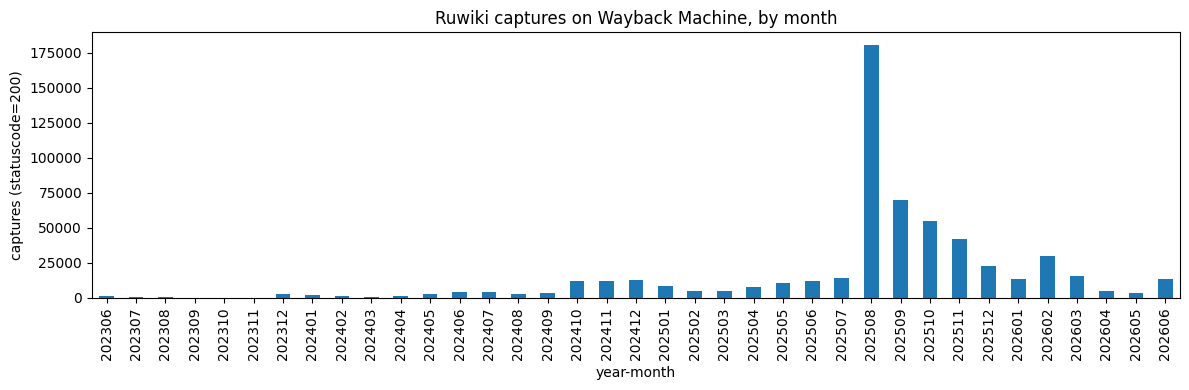

In [10]:
import matplotlib.pyplot as plt

captures_200['year_month'] = captures_200['timestamp'].str[:6]
monthly_counts = captures_200.groupby('year_month').size().sort_index()

fig, ax = plt.subplots(figsize=(12, 4))
monthly_counts.plot(kind='bar', ax=ax)
ax.set_title('Ruwiki captures on Wayback Machine, by month')
ax.set_xlabel('year-month')
ax.set_ylabel('captures (statuscode=200)')
plt.tight_layout()
plt.show()

## Step 5 — save the full index

This is just the *index* (metadata: which article, which timestamp, content-hash) — not the downloaded HTML itself. Feeding this into `wayback_harvest.py` to actually download specific articles' content is a separate, deliberate step (so we don't accidentally try to download hundreds of thousands of pages at once).

In [11]:
final_path = DATA_DIR / 'cdx_full_index.parquet'
full_df.to_parquet(final_path)
print(f'saved {len(full_df)} rows to {final_path}')

saved 675272 rows to ..\data\interim\cdx_full_index.parquet
